In [ ]:
import pandas as pd
import os
from cluster_weather_years.constants import BASE_OUTPUT, HYDROLOGICAL_YEARS
from cluster_weather_years.evaluation import (
    plot_results_with_pareto,
    plot_lollipop_by_country,
)
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# RUNNAME = "run_NL_30y_20260121_1726"
RUNNAME_ = "run_NW_Europe_30y_20260122_1602"
fname_results = os.path.join(BASE_OUTPUT, RUNNAME_, "all_year_selections_scored.csv")
fname_country_results = os.path.join(
    BASE_OUTPUT, RUNNAME_, "all_year_selections_country_scores.csv"
)
df_results = pd.read_csv(fname_results, index_col=0)
df_country_results = pd.read_csv(fname_country_results, index_col=0)

# retrieve variable order list
variable_order = (
    pd.read_csv(os.path.join(BASE_OUTPUT, RUNNAME_, "variable_order.csv"))
    .values.flatten()
    .tolist()
)

# Load run settings
fname_settings = os.path.join(BASE_OUTPUT, RUNNAME_, "RUN_SETTINGS_of_run.py")
with open(fname_settings) as f:
    exec(f.read())

list_cols = ["d_mean", "qq_mae", "energy_distance_score", "qq_mae_high", "qq_mae_low"]
for col in list_cols:
    col_max = "max_" + col
    df_results[col_max] = df_results[col].apply(lambda x: max(eval(x)))

In [4]:
# load df_ref, for calculation country-level Wasserstein scores
df_daily = pd.read_parquet(DF_PROD_DEMAND_FNAME)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year in @HYDROLOGICAL_YEARS")
df_daily = df_daily.set_index(["model", "Date"])

vars_non_nan = [var for var in VARS_TO_MATCH if not df_daily[var].isna().all()]
df_ref = df_daily[["Hydrological_year", "Calendar_year"] + VARS_TO_MATCH]

In [5]:
df_results[["selection_source", "wasserstein_seasonal", "wasserstein"]].sort_values(
    "wasserstein_seasonal"
).head(10)

,selection_source,wasserstein_seasonal,wasserstein
69,simulated_annealing,2.662045,1.832518
78,simulated_annealing,2.684275,1.981967
88,simulated_annealing,2.711965,1.978710
81,simulated_annealing,2.712433,2.064497
66,simulated_annealing,2.736398,2.003907
87,simulated_annealing,2.776189,1.732561
74,simulated_annealing,2.781671,2.062805
55,simulated_annealing,2.798901,1.940787
86,simulated_annealing,2.799528,2.075261
85,simulated_annealing,2.801253,2.075592


## Simple scatter plots

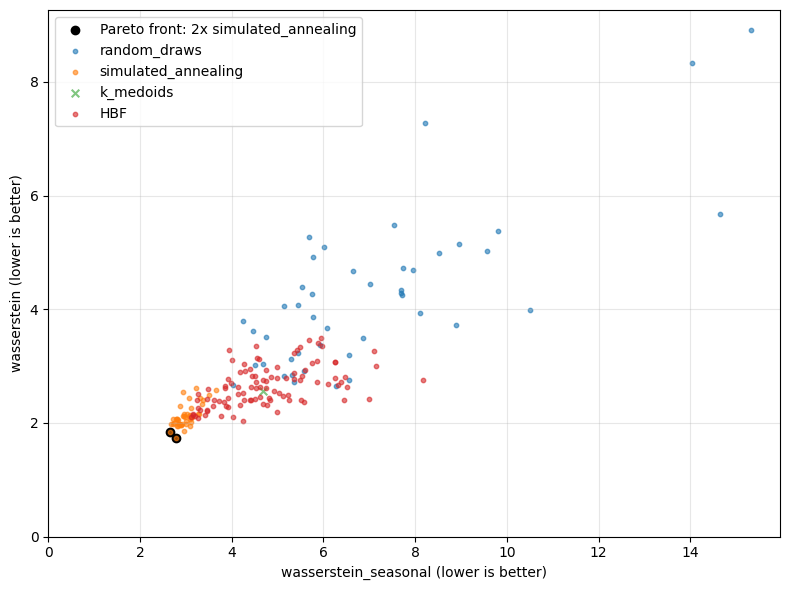

In [6]:
plot_results_with_pareto(df_results, "wasserstein_seasonal", "wasserstein")

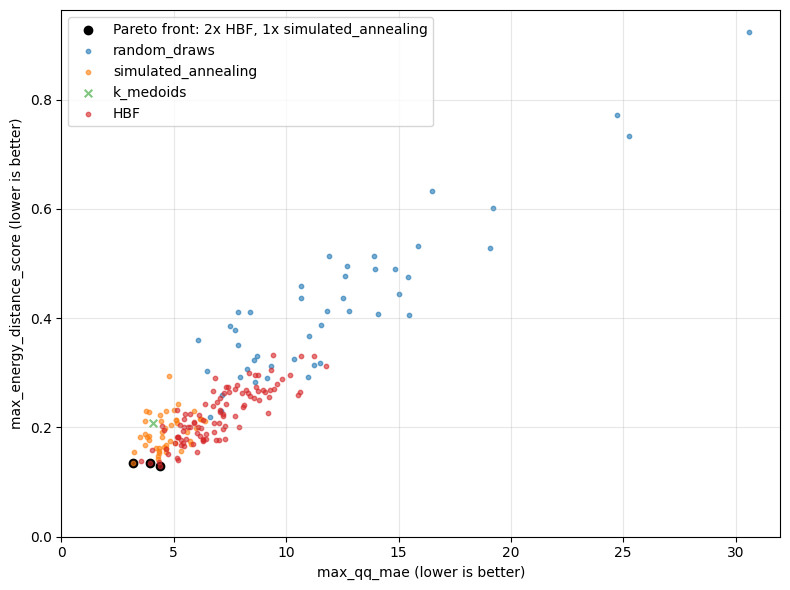

In [7]:
plot_results_with_pareto(df_results, "max_qq_mae", "max_energy_distance_score")

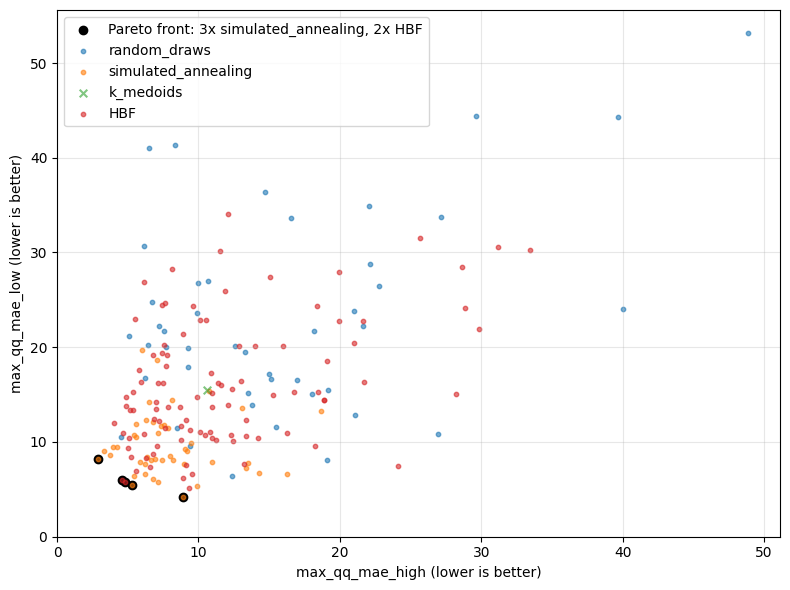

In [8]:
plot_results_with_pareto(df_results, "max_qq_mae_high", "max_qq_mae_low")

## Lollipop plots

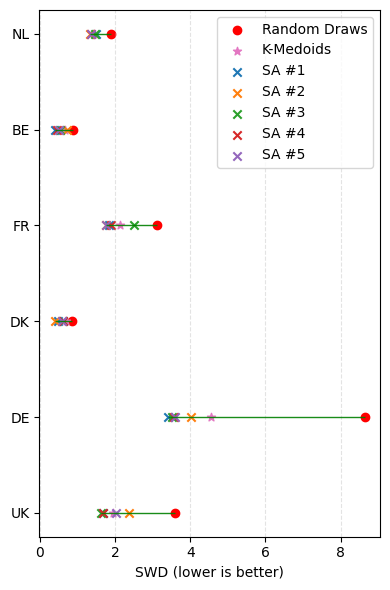

In [ ]:
plot_lollipop_by_country(
    df_results, df_country_results, MATCH_COUNTRIES, "wasserstein", "SWD"
)

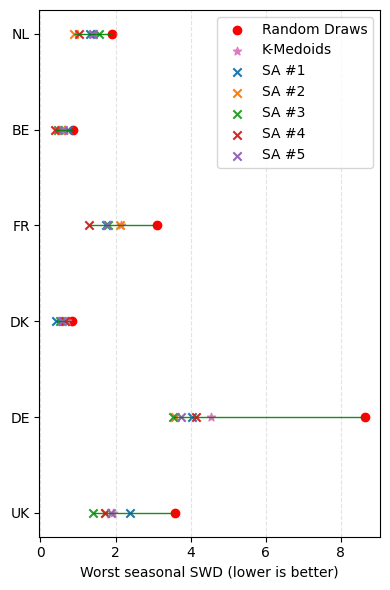

In [ ]:
plot_lollipop_by_country(
    df_results,
    df_country_results,
    MATCH_COUNTRIES,
    "wasserstein_seasonal",
    "Worst seasonal SWD",
)

##### Plots for country: NL #####
##### Plots for country: BE #####
##### Plots for country: FR #####
##### Plots for country: DK #####
##### Plots for country: DE #####
##### Plots for country: UK #####


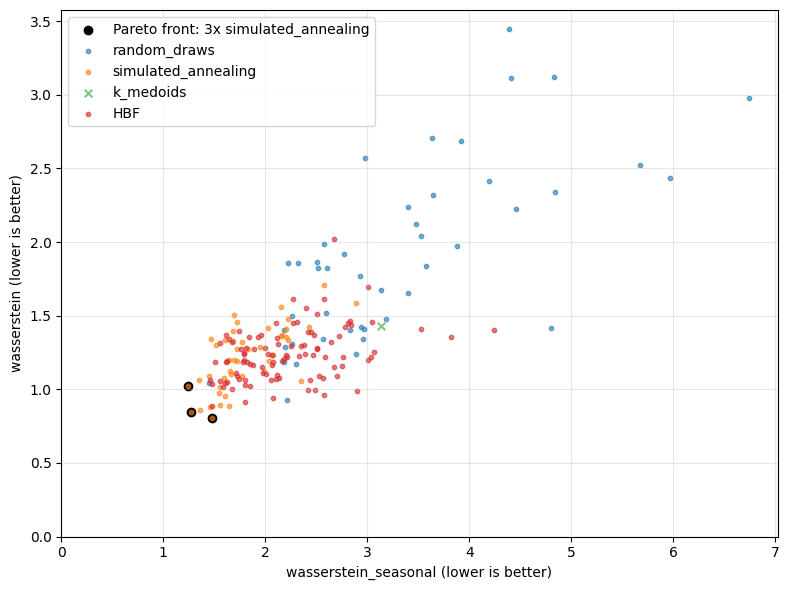

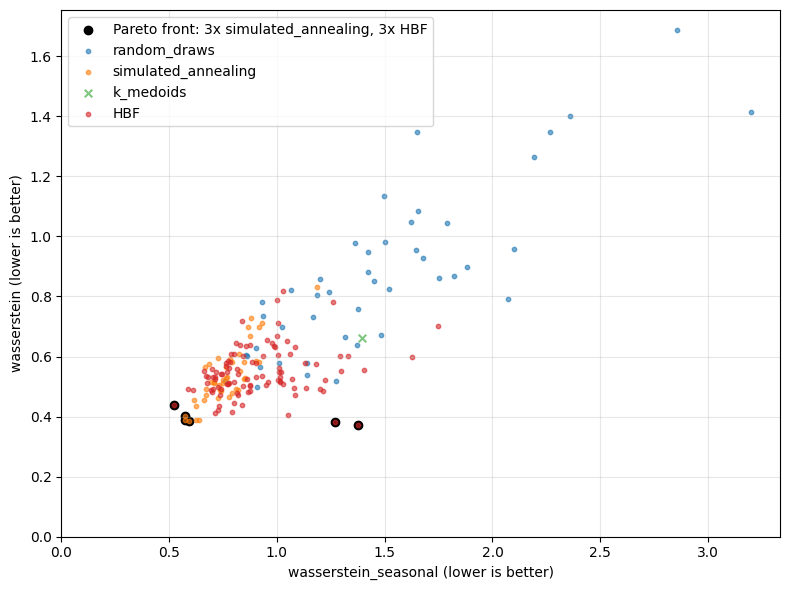

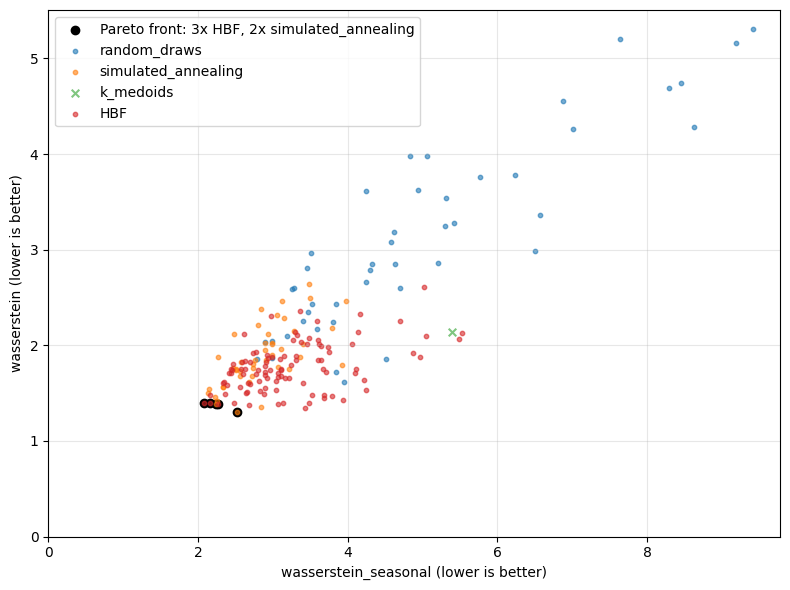

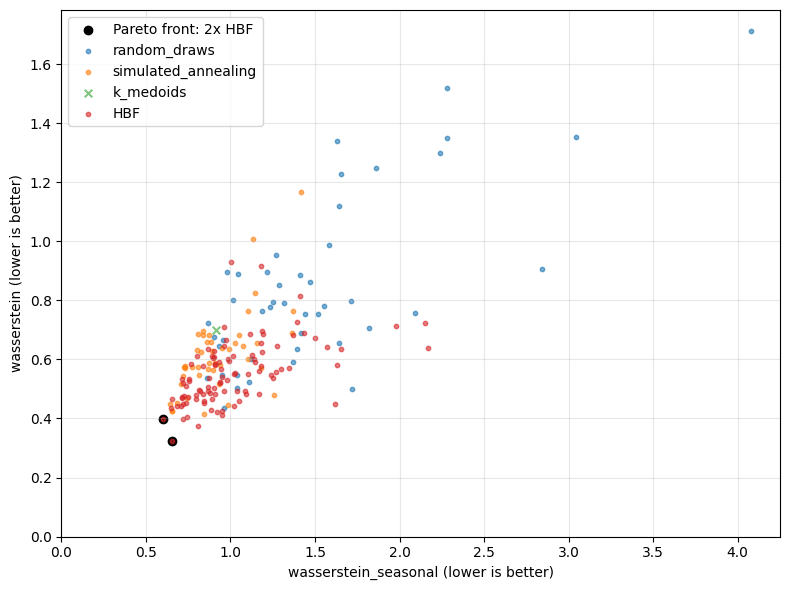

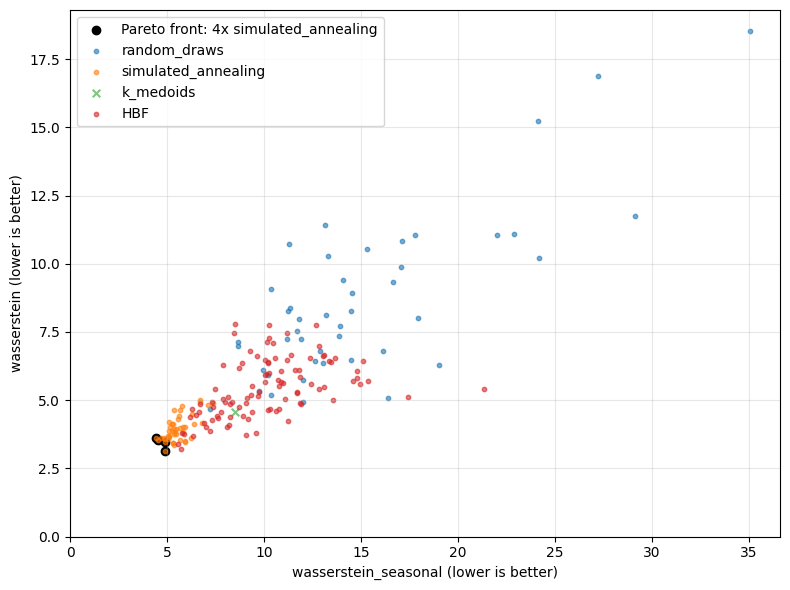

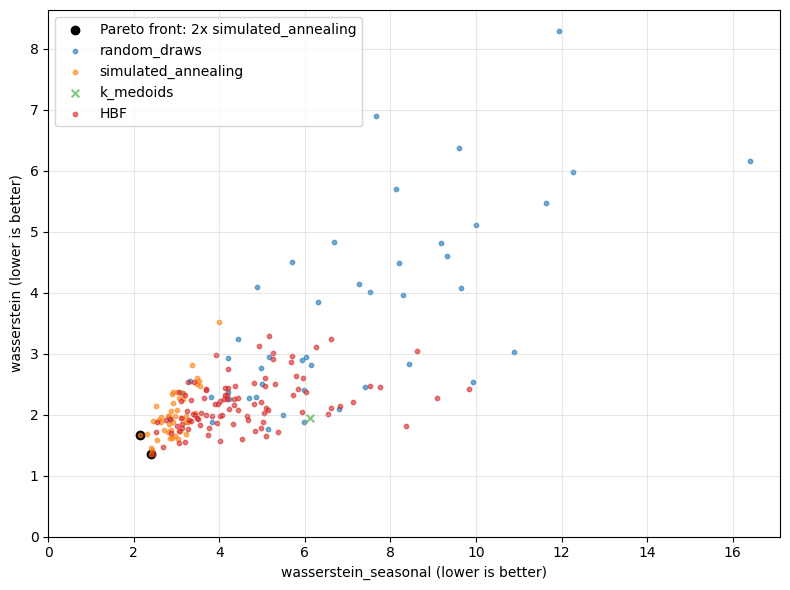

In [ ]:
for country in MATCH_COUNTRIES:
    df_country = df_country_results.query("country == @country")
    print(f"##### Plots for country: {country} #####")
    plot_results_with_pareto(
        df_country,
        "wasserstein_seasonal",
        "wasserstein",
    )